In [1]:
import numpy as np

In [2]:
data = np.loadtxt("Concrete_Data.csv", delimiter=",", skiprows=1)

In [3]:
data.shape
rng = np.random.default_rng(seed=42)
rng.shuffle(data)

In [4]:
X = data[:1000,:8]
X[0]

array([250. ,   0. ,  95.7, 191.8,   5.3, 948.9, 857.2, 100. ])

In [5]:
T = data[:1000,8]
T.shape

(1000,)

In [6]:
X[0]

array([250. ,   0. ,  95.7, 191.8,   5.3, 948.9, 857.2, 100. ])

In [7]:
mean = np.mean(X,axis =0)
std = np.std(X,axis=0)
std

array([104.33244649,  86.2567454 ,  64.03803854,  21.16963433,
         5.93525348,  78.06872329,  79.84172021,  62.19389565])

The input data is normalized. For each column its mean and standard deviation is calculated and subtracted from each corressponding data point in the corresponding column

In [8]:
X = (X - mean) / std

First we are going train out model using maximum likelihood to predict concerte strength then we will use Bayesian regression.
We assume that are data is identically and idependently disdtributed


So the likelihood function: $$
\begin{aligned}
p(\vec{T}\mid \vec{X},\vec{w})
&= \prod_{n=1}^{N} p(t_n\mid \vec{x}_n,\vec{w}) \\
&= \prod_{n=1}^{N}
\mathcal{N}\left(
t_n \mid \vec{w}^{\,T}\phi(\vec{x_n}),\,\beta^{-1}
\right).
\end{aligned}
$$
where $\begin{aligned}\phi(x_n)\end{aligned}$ is the basis function applied to our data point $x_n$, $\vec{T}$ is the dataset containing all labels $t_n$ from $1,...,N$ and $\vec{X}$ contains the corresponding training data vector $x_n$. The code snippet below applies the basis function to each point in the training set. Note that $\phi(\vec{x_n})$ is a column vector and so is $\vec{x_n}$

In [9]:
phi = []; #4th order polynomial estimate
for xn in X:
    phi_n = [1]
    for i in range(X.shape[1]):
        phi_n.append(xn[i])
    for i in range(X.shape[1]):
        for j in range(i,X.shape[1]):
            phi_n.append(xn[i]*xn[j])
    for i in range(X.shape[1]):
        for j in range(i,X.shape[1]):
            for k in range(j,X.shape[1]):
                phi_n.append(xn[i]*xn[j]*xn[k])
    for i in range(X.shape[1]):
        for j in range(i,X.shape[1]):
            for k in range(j,X.shape[1]):
                for m in range(k,X.shape[1]):
                     phi_n.append(xn[i]*xn[j]*xn[k]*xn[m]);
    phi.append(phi_n)
   
    

In [10]:
phi = np.array(phi)

In [11]:
phi.shape

(1000, 495)

$$
\begin{aligned}
\ln p(\vec{T}\mid \vec{X},\vec{w})
&= \frac{N}{2}\ln\left(\frac{\beta}{2\pi}\right)
-\frac{\beta}{2}\sum_{n=1}^{N}
\left(\vec{w}^{\,T}\phi(\vec{x_n})-t_n\right)^2
\\[1em]
\nabla_{\vec{w}}\ln p(\vec{T}\mid \vec{X},\vec{w})
&= {-\beta} \sum_{n=1}^{N}
\left(\vec{w}^{\,T}\phi(\vec{x_n})-t_n\right)\phi(\vec{x_n})
= \vec{0}
\\[1em]
\implies\quad
\left(\sum_{n=1}^{N}\phi(\vec{x_n})\phi(\vec{x_n})^T\right)\vec{w}
&= \sum_{n=1}^{N}t_n\phi(\vec{x_n})
\\[1em]
\vec{w}_{\mathrm{ML}}
&= \left(\sum_{n=1}^{N}\phi(\vec{x_n})\phi(\vec{x_n})^T\right)^{-1}
\left(\sum_{n=1}^{N}t_n\phi(\vec{x_n})\right).
\end{aligned}
$$

In [12]:
#Train with maximum likelihood for now
#phi n is a column vector
A = np.zeros((phi.shape[1],phi.shape[1]),dtype='float64')
for row in phi:
    phi_n = row.reshape((phi.shape[1],1))
    A+= phi_n@phi_n.T
    
B = np.zeros((phi.shape[1],1),dtype='float64')
for n in range(T.shape[0]):
    phi_n = phi[n].reshape((phi.shape[1],1))
    B+= T[n]*phi_n

In [13]:
w = np.linalg.inv(A)@B

In [14]:
w.shape

(495, 1)

$$
\begin{aligned}
\frac{\partial \ln p(\vec{T}\mid \vec{X},\vec{w})}{\partial \beta}
&= \frac{N}{2\beta}
-\frac{1}{2}\sum_{n=1}^{N}
\left(\vec{w}_{\mathrm{ML}}^{\,T}\phi(x_n)-t_n\right)^2
= 0
\\[1em]
\implies\quad
\frac{1}{\beta_{\mathrm{ML}}}
&= \frac{1}{N}\sum_{n=1}^{N}
\left(\vec{w}_{\mathrm{ML}}^{\,T}\phi(x_n)-t_n\right)^2.
\end{aligned}
$$

In [15]:
beta_inv = 0
for n in range(phi.shape[0]):
    phi_n = phi[n].reshape((phi.shape[1],1));
    beta_inv+=(np.dot(w.T,phi_n)-T[n])**2
beta_inv/=phi.shape[0]
    

In [16]:
test_x = data[1000:,:8]
test_y = data[1000:,8]
test_x = (test_x - mean) / std

In [17]:
print(test_x.shape)
print(test_y.shape)

(30, 8)
(30,)


Applying the basis function now to our testing data


In [18]:
phi_test = []; #4th order polynomial estimate
for xn in test_x:
    phi_n = [1]
    for i in range(test_x.shape[1]):
        phi_n.append(xn[i])
    for i in range(test_x.shape[1]):
        for j in range(i,test_x.shape[1]):
            phi_n.append(xn[i]*xn[j])
    for i in range(test_x.shape[1]):
        for j in range(i,test_x.shape[1]):
            for k in range(j,test_x.shape[1]):
                phi_n.append(xn[i]*xn[j]*xn[k])
    for i in range(test_x.shape[1]):
        for j in range(i,test_x.shape[1]):
            for k in range(j,test_x.shape[1]):
                for m in range(k,test_x.shape[1]):
                     phi_n.append(xn[i]*xn[j]*xn[k]*xn[m]);
    phi_test.append(phi_n)

In [19]:
phi_test = np.array(phi_test)
phi_test.shape

(30, 495)

In [20]:
phi_test_n = phi_test[0]
phi_test_n.shape

(495,)

In [21]:
phi_test_n = phi_test_n.reshape((phi_test_n.shape[0],1))
pred = w.T@phi_test_n
print(pred)
print(test_y[0])

[[11.6753225]]
12.18


In [22]:
predictions = (phi_test @ w).ravel()

rmse = np.sqrt(np.mean((predictions - test_y)**2))

print("Test RMSE:", rmse)
print("First five predictions:", predictions[:5])
print("First five actual values:", test_y[:5])

Test RMSE: 4.397409898529868
First five predictions: [11.6753225  20.5779358  50.07573944 30.78236391 17.80867113]
First five actual values: [12.18 24.99 53.69 27.77 21.02]


In [23]:
std

array([104.33244649,  86.2567454 ,  64.03803854,  21.16963433,
         5.93525348,  78.06872329,  79.84172021,  62.19389565])

In [24]:
T.shape

(1000,)

Now I am going to define a posterior distribution over the weights
I have dropped the dependence on the inputs $\vec{X}$ and on $\beta$ to keep the notation uncluttered
$$
\begin{aligned}
p(\vec{w}\mid\vec{T})
&\propto p(\vec{T}\mid\vec{w})\,p(\vec{w}),
\\[1em]
p(\vec{w})
&= \mathcal{N}(\vec{w}\mid\vec{m}_0,S_0),
\\[1em]
p(\vec{T}\mid\vec{w})
&= \prod_{n=1}^{N}
\mathcal{N}\left(t_n\mid\vec{w}^{\,T}\phi(x_n),\beta^{-1}\right)
\\[1em]
&= \left(\frac{\beta}{2\pi}\right)^{N/2}
\exp\left[
-\frac{\beta}{2}\sum_{n=1}^{N}
\left(\vec{w}^{\,T}\phi(x_n)-t_n\right)^2
\right].
\end{aligned}
$$

$$
\begin{aligned}
p(\vec{w}\mid\vec{T})
&\propto \exp\left[
-\frac{\beta}{2}\sum_{n=1}^{N}
\left(
\vec{w}^{\,T}\phi(x_n)\phi(x_n)^T\vec{w}
+t_n^2-2t_n\vec{w}^{\,T}\phi(x_n)
\right)
-\frac{1}{2}(\vec{w}-\vec{m}_0)^T
S_0^{-1}(\vec{w}-\vec{m}_0)
\right]
\\[1em]
&\propto \exp\left[
-\frac{\beta}{2}\sum_{n=1}^{N}
\left(
\vec{w}^{\,T}\phi(x_n)\phi(x_n)^T\vec{w}
+t_n^2-2t_n\vec{w}^{\,T}\phi(x_n)
\right)
-\frac{1}{2}\vec{w}^{\,T}S_0^{-1}\vec{w}
+\vec{w}^{\,T}S_0^{-1}\vec{m}_0
-\frac{1}{2}\vec{m}_0^{\,T}S_0^{-1}\vec{m}_0
\right]
\\[1em]
&\propto \exp\left[
-\frac{1}{2}\vec{w}^{\,T}
\left(
\beta\sum_{n=1}^{N}\phi(x_n)\phi(x_n)^T+S_0^{-1}
\right)\vec{w}
+\vec{w}^{\,T}
\left(
\beta\sum_{n=1}^{N}t_n\phi(x_n)+S_0^{-1}\vec{m}_0
\right)
\right].
\end{aligned}
$$

$$
\begin{aligned}
p(\vec{w}\mid\vec{T})
&= \mathcal{N}(\vec{w}\mid\vec{m}_N,S_N),
\\[1em]
S_N^{-1}
&= \beta\sum_{n=1}^{N}\phi(x_n)\phi(x_n)^T+S_0^{-1},
\\[1em]
\vec{m}_N
&= S_N\left(
\beta\sum_{n=1}^{N}t_n\phi(x_n)+S_0^{-1}\vec{m}_0
\right).
\end{aligned}
$$
The above was general case derivation of the equation for a prior with arbitary mean and covariance. Here I am going to define my prior
to be a gaussian with zero mean and following covariance
$$
p(\vec{w}\mid\alpha)
= \mathcal{N}\left(
\vec{w}\mid
\underbrace{\vec{0}}_{\vec{m}_0},
\underbrace{\alpha^{-1}I}_{S_0}
\right).
$$

$$
\begin{aligned}
\implies\quad
\vec{m}_N
&= S_N\left(\beta\sum_{n=1}^{N}t_n\phi(x_n)\right),
\\[1em]
S_N^{-1}
&= \alpha I+\beta\sum_{n=1}^{N}\phi(x_n)\phi(x_n)^T.
\end{aligned}
$$

In [25]:
#Posterior Distribution. Assumption of an isotropic gaussian prior
alpha = 0.021
Sn_inv = np.identity(phi.shape[1])*alpha
for i in range(phi.shape[0]):
    phi_n = phi[i].reshape((phi.shape[1],1))
    Sn_inv+= (phi_n@phi_n.T)*(1/beta_inv)

mn = np.zeros((phi.shape[1],1))
for i in range(phi.shape[0]):
    phi_n = phi[i].reshape((phi.shape[1],1))
    mn+=phi_n*T[i]

mn = (1/beta_inv)*np.linalg.inv(Sn_inv)@mn
    

In [26]:
mn.shape

(495, 1)

for a point estimate of $\vec{w}$ we use the Maximum a posterior. The mean of a gaussian posterior is its mode 

In [27]:
w_map = mn
predictions = (phi_test @ w_map).ravel()

rmse = np.sqrt(np.mean((predictions - test_y)**2))

print("Test RMSE:", rmse)
print("First five predictions:", predictions[:5])
print("First five actual values:", test_y[:5])

Test RMSE: 3.929032963852745
First five predictions: [12.83073934 21.7252294  51.29783705 31.00893852 17.10273075]
First five actual values: [12.18 24.99 53.69 27.77 21.02]


In [28]:
phi_test.shape[1]

495

We can also try to find alpha by maximizing the evidence function. I have dropped the dependence on input $\vec{X}$ for clarity
$$
\begin{aligned}
p(\vec{T},\vec{w}\mid\alpha,\beta)
&= p(\vec{T}\mid\vec{w},\beta)\,
p(\vec{w}\mid\alpha)
\\[1em]
p(\vec{T}\mid\alpha,\beta)
&= \int p(\vec{T}\mid\vec{w},\beta)\,
p(\vec{w}\mid\alpha)\,d\vec{w}
\\[1em]
&= \int
\left(\frac{\beta}{2\pi}\right)^{N/2}
\exp\left[
-\frac{\beta}{2}\sum_{n=1}^{N}
\left(\vec{w}^{\,T}\phi(x_n)-t_n\right)^2
\right]
\left(\frac{\alpha}{2\pi}\right)^{W/2}
\exp\left[
-\frac{\alpha}{2}\vec{w}^{\,T}\vec{w}
\right]\,d\vec{w}
\\[1em]
&= \left(\frac{\beta}{2\pi}\right)^{N/2}
\left(\frac{\alpha}{2\pi}\right)^{W/2}
\int \exp\left[
-\frac{\beta}{2}\sum_{n=1}^{N}
\left(\vec{w}^{\,T}\phi(x_n)-t_n\right)^2
-\frac{\alpha}{2}\vec{w}^{\,T}\vec{w}
\right]\,d\vec{w}
\\[1em]
&= \left(\frac{\beta}{2\pi}\right)^{N/2}
\left(\frac{\alpha}{2\pi}\right)^{W/2}
\int \exp\left[-E(\vec{w})\right]\,d\vec{w},
\\[1em]
\text{where}\qquad
E(\vec{w})
&= \frac{\beta}{2}\sum_{n=1}^{N}
\left(\vec{w}^{\,T}\phi(x_n)-t_n\right)^2
+\frac{\alpha}{2}\vec{w}^{\,T}\vec{w}.
\end{aligned}
$$

$$
\begin{aligned}
E(\vec{w})
&= \frac{1}{2}\vec{w}^{\,T}
\left(
\beta\sum_{n=1}^{N}\phi(x_n)\phi(x_n)^T+\alpha I
\right)\vec{w}
-\vec{w}^{\,T}
\left(\beta\sum_{n=1}^{N}t_n\phi(x_n)\right)
+\frac{\beta}{2}\sum_{n=1}^{N}t_n^2,
\\[1em]
A
&= \alpha I+\beta\sum_{n=1}^{N}\phi(x_n)\phi(x_n)^T,
\\[1em]
\vec{\mu}_N
&= \beta A^{-1}\sum_{n=1}^{N}t_n\phi(x_n).
\end{aligned}
$$

$$
\begin{aligned}
E(\vec{w})
&= \frac{1}{2}(\vec{w}-\vec{\mu}_N)^T
A(\vec{w}-\vec{\mu}_N)
-\frac{1}{2}\vec{\mu}_N^{\,T}A\vec{\mu}_N
+\frac{\beta}{2}\sum_{n=1}^{N}t_n^2
\\[1em]
&= E(\vec{\mu}_N)
+\frac{1}{2}(\vec{w}-\vec{\mu}_N)^T
A(\vec{w}-\vec{\mu}_N),
\\[1em]
\text{where}\qquad
E(\vec{\mu}_N)
&= \frac{\beta}{2}\sum_{n=1}^{N}t_n^2
-\frac{1}{2}\vec{\mu}_N^{\,T}A\vec{\mu}_N.
\end{aligned}
$$
Now we will substitue this expression back into our integral and take the log of the evidence function

$$
\begin{aligned}
p(\vec{t}\mid\alpha,\beta)
&= \left(\frac{\beta}{2\pi}\right)^{N/2}
\left(\frac{\alpha}{2\pi}\right)^{W/2}
\exp\left[-E(\vec{\mu}_N)\right]
\int \exp\left[
-\frac{1}{2}(\vec{w}-\vec{\mu}_N)^T
A(\vec{w}-\vec{\mu}_N)
\right]\,d\vec{w}
\\[1em]
&= \left(\frac{\beta}{2\pi}\right)^{N/2}
\left(\frac{\alpha}{2\pi}\right)^{W/2}
\exp\left[-E(\vec{\mu}_N)\right]
(2\pi)^{W/2}|A|^{-1/2}.
\end{aligned}
$$

$$
\ln p(\vec{T}\mid\alpha,\beta)
= \frac{W}{2}\ln\alpha
+\frac{N}{2}\ln\beta
-E(\vec{\mu}_N)
-\frac{1}{2}\ln|A|
-\frac{N}{2}\ln(2\pi).
$$

Now I will maximize the evidence function wrt to $\alpha$. We can evaluate the determinant of $A$ using the product of its eigen values so using the below eigen value equation for $A$ and then differentiating wrt to $\alpha$ we get

$$
\begin{aligned}
\left(\beta\sum_{n=1}^{N}\phi(x_n)\phi(x_n)^T\right)\vec{u}_i
&= \lambda_i\vec{u}_i,
\\[1em]
A\vec{u}_i
&= \alpha\vec{u}_i+\lambda_i\vec{u}_i
\\
&= (\alpha+\lambda_i)\vec{u}_i.
\end{aligned}
$$

$$
\begin{aligned}
\frac{d}{d\alpha}\ln|A|
&= \frac{d}{d\alpha}
\ln\left(\prod_{i=1}^{W}(\alpha+\lambda_i)\right)
\\[1em]
&= \sum_{i=1}^{W}\frac{1}{\alpha+\lambda_i}.
\end{aligned}
$$

$$
\begin{aligned}
\frac{\partial\ln p(\vec{t}\mid\alpha,\beta)}{\partial\alpha}
&= \frac{W}{2\alpha}
-\frac{1}{2}\vec{\mu}_N^{\,T}\vec{\mu}_N
-\frac{1}{2}\sum_{i=1}^{W}\frac{1}{\alpha+\lambda_i}
= 0,
\\[1em]
W-\sum_{i=1}^{W}\frac{\alpha}{\alpha+\lambda_i}
&= \alpha\vec{\mu}_N^{\,T}\vec{\mu}_N,
\\[1em]
\alpha
&= \frac{\gamma}{\vec{\mu}_N^{\,T}\vec{\mu}_N},
\\[1em]
\gamma
&= \sum_{i=1}^{W}\frac{\lambda_i}{\alpha+\lambda_i}.
\end{aligned}
$$

In [29]:
#Re-estimate alpha using the evidence approximation
iterations = 0
alpha = 1
max_iterations = 1000
tolerance = 1e-6
#first calculating the eigen values required
temp = np.zeros((phi.shape[1],phi.shape[1]));
beta = 1/beta_inv
for row in phi:
    phi_xn = row.reshape((phi.shape[1],1))
    temp+= beta*(phi_xn@phi_xn.T)
temp2 = np.zeros((phi.shape[1],1))
for i in range(phi.shape[0]):
    phi_xn = phi[i].reshape((phi.shape[1],1));
    temp2+= T[i]*phi_xn;


lam, _ = np.linalg.eig(temp)
lam = np.maximum(lam,0.0)

while(iterations<max_iterations):
    A = alpha*np.identity(phi.shape[1]) + temp
    mu_n = beta*np.linalg.inv(A)@temp2
    gamma = 0
    for lam_i in lam:
        gamma+= lam_i/(alpha+lam_i)
    alpha_new = gamma/(mu_n.T@mu_n)
    iterations+=1
    if(abs(alpha-alpha_new)<tolerance*alpha):
        alpha = alpha_new;
        break;
    alpha = alpha_new
                
print(alpha)
#Re calculate the posterior
Sn_inv = np.identity(phi.shape[1])*alpha
for i in range(phi.shape[0]):
    phi_n = phi[i].reshape((phi.shape[1],1))
    Sn_inv+= (phi_n@phi_n.T)*(1/beta_inv)

mn = np.zeros((phi.shape[1],1))
for i in range(phi.shape[0]):
    phi_n = phi[i].reshape((phi.shape[1],1))
    mn+=phi_n*T[i]

mn = (1/beta_inv)*np.linalg.inv(Sn_inv)@mn
w_map = mn
predictions = (phi_test @ w_map).ravel()

rmse = np.sqrt(np.mean((predictions - test_y)**2))

print("Test RMSE:", rmse)
print("First five predictions:", predictions[:5])
print("First five actual values:", test_y[:5])

[[0.05909497]]
Test RMSE: 4.101234251792516
First five predictions: [13.9685853  21.98562591 51.27714671 31.35624525 17.45099128]
First five actual values: [12.18 24.99 53.69 27.77 21.02]


Now I am defining a predictive distribution to predict a new target $t'$ and new input $\vec{x'}$
$$
\begin{aligned}
p(t',w\mid \vec{x'},\alpha,\beta,\vec{T})
&= p(t'\mid\vec{w},\vec{x'},\beta)\,
p(\vec{w}\mid\vec{T},\alpha)
\\[1em]
p(t'\mid \vec{x'},\alpha,\beta,\vec{T})
&= \int p(t'\mid\vec{w},\vec{x'},\beta)\,
p(\vec{w}\mid\vec{T},\alpha)\,dw
\\[1em]
&= \int
\mathcal{N}\left(t'\mid w^T\phi(\vec{x'}),\beta^{-1}\right)
\mathcal{N}\left(\vec{w}\mid \vec{m_N},S_N\right)\,dw
\\[1em]
&= \mathcal{N}\left(
t'\mid \phi(\vec{x'})^T \vec{m_N},\,
\beta^{-1}+\phi(x')^T S_N \phi(x')
\right).
\end{aligned}
$$

In [30]:
#Predictive distribution. Normal distribution
u = np.linalg.inv(Sn_inv)
for i in range(phi_test.shape[0]):
    phi_x_ = phi_test[i].reshape((phi_test.shape[1],1))
    mu = phi_x_.T@mn;
    variance = beta_inv+ phi_x_.T@u@phi_x_
    true_val = test_y[i]
    print(f"Mean: {mu} Variance {variance} True Value {true_val} \n")

Mean: [[13.9685853]] Variance [[9.03410446]] True Value 12.18 

Mean: [[21.98562591]] Variance [[6.26657524]] True Value 24.99 

Mean: [[51.27714671]] Variance [[32.05663312]] True Value 53.69 

Mean: [[31.35624525]] Variance [[6.73703092]] True Value 27.77 

Mean: [[17.45099128]] Variance [[8.02485386]] True Value 21.02 

Mean: [[48.48607033]] Variance [[9.93642983]] True Value 46.23 

Mean: [[19.11543477]] Variance [[6.28133822]] True Value 23.4 

Mean: [[62.60878882]] Variance [[16.01939009]] True Value 66.42 

Mean: [[77.7992551]] Variance [[6.50303451]] True Value 79.3 

Mean: [[29.15701934]] Variance [[7.6254792]] True Value 32.82 

Mean: [[23.58862406]] Variance [[21.6710904]] True Value 23.25 

Mean: [[46.71481543]] Variance [[8.97697313]] True Value 46.9 

Mean: [[46.44443985]] Variance [[7.66945466]] True Value 47.78 

Mean: [[7.84682714]] Variance [[6.71712985]] True Value 4.9 

Mean: [[45.25665031]] Variance [[10.36772104]] True Value 43.7 

Mean: [[18.79066581]] Variance [

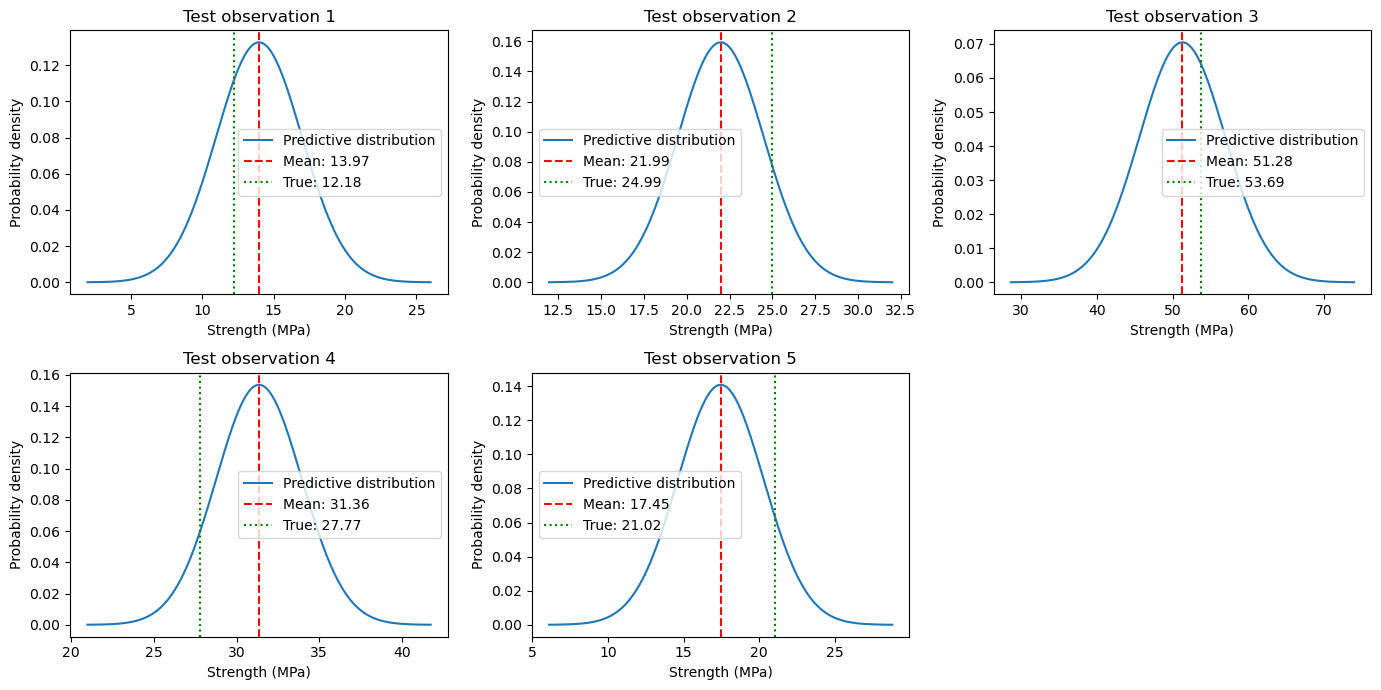

In [31]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.ravel()

for i in range(5):
    phi_x_ = phi_test[i].reshape(-1, 1)

    mu = (phi_x_.T @ mn).item()

    # Equivalent to inv(Sn_inv) @ phi_x_
    u = np.linalg.solve(Sn_inv, phi_x_)

    variance = (beta_inv + phi_x_.T @ u).item()
    sigma = np.sqrt(variance)

    true_val = test_y[i]

    # Include both the distribution and true value in the plot range
    lower = min(mu - 4*sigma, true_val - sigma)
    upper = max(mu + 4*sigma, true_val + sigma)

    t = np.linspace(lower, upper, 500)

    density = np.exp(
        -0.5 * ((t - mu) / sigma)**2
    ) / (sigma * np.sqrt(2*np.pi))

    ax = axes[i]

    ax.plot(t, density, label="Predictive distribution")
    ax.axvline(
        mu, color="red", linestyle="--",
        label=f"Mean: {mu:.2f}"
    )
    ax.axvline(
        true_val, color="green", linestyle=":",
        label=f"True: {true_val:.2f}"
    )

    ax.set_title(f"Test observation {i + 1}")
    ax.set_xlabel("Strength (MPa)")
    ax.set_ylabel("Probability density")
    ax.legend()

axes[5].axis("off")
plt.tight_layout()
plt.show()

Now we are going to define a prior over both our weights and $\beta$. We are using the conjugate normal-gamma prior

$$
\begin{aligned}
p(w,\beta)
&= \mathcal{N}\left(w\mid m_0,\beta^{-1}S_0\right)
\operatorname{Gam}(\beta\mid a_0,b_0),
\\[1em]
p(w,\beta\mid\vec{T})
&\propto p(\vec{T}\mid w,\beta)\,p(w,\beta)
\\[1em]
&\propto
\left(\frac{\beta}{2\pi}\right)^{N/2}
\exp\left[
-\frac{\beta}{2}\sum_{n=1}^{N}
\left(w^T\phi(x_n)-t_n\right)^2
\right]
\frac{\beta^{W/2}}{(2\pi)^{W/2}|S_0|^{1/2}}
\\
&\qquad {}\times
\exp\left[
-\frac{1}{2}(w-m_0)^T\beta S_0^{-1}(w-m_0)
\right]
\frac{b_0^{a_0}}{\Gamma(a_0)}
\beta^{a_0-1}\exp(-b_0\beta)
\\[1em]
&\propto \beta^{N/2+a_0-1}
\exp\left[
-\frac{\beta}{2}w^T
\left(
\sum_{n=1}^{N}\phi(x_n)\phi(x_n)^T+S_0^{-1}
\right)w
+\beta w^T
\left(
S_0^{-1}m_0+\sum_{n=1}^{N}t_n\phi(x_n)
\right)
\right]
\\
&\qquad {}\times
\exp\left[
-\beta\left(
b_0+\frac{1}{2}
\left(
\sum_{n=1}^{N}t_n^2+m_0^TS_0^{-1}m_0
\right)
\right)
\right].
\end{aligned}
$$

$$
\begin{aligned}
p(w,\beta\mid\vec{T})
&= \mathcal{N}\left(w\mid m_N,\beta^{-1}S_N\right)
\operatorname{Gam}(\beta\mid a_N,b_N),
\\[1em]
S_N^{-1}
&= \sum_{n=1}^{N}\phi(x_n)\phi(x_n)^T+S_0^{-1},
\\[1em]
m_N
&= S_N\left(
S_0^{-1}m_0+\sum_{n=1}^{N}t_n\phi(x_n)
\right),
\\[1em]
a_N
&= \frac{N}{2}+a_0,
\\[1em]
b_N
&= b_0+\frac{1}{2}\left(
\sum_{n=1}^{N}t_n^2
+m_0^TS_0^{-1}m_0
-m_N^TS_N^{-1}m_N
\right).
\end{aligned}
$$


Now in our case $\vec{m_0}$ has zero mean and $S_0$ is given by $\alpha^{-1}I$
$$
\begin{aligned}
\implies\quad S_N^{-1}
&= \sum_{n=1}^{N}\phi(x_n)\phi(x_n)^T+\alpha I,
\\[1em]
m_N
&= S_N\left(\sum_{n=1}^{N}t_n\phi(x_n)\right),
\\[1em]
b_N
&= b_0+\frac{1}{2}\left(
\sum_{n=1}^{N}t_n^2-m_N^TS_N^{-1}m_N
\right).
\end{aligned}
$$

In [32]:
#Prior over both weights and variance beta
#Posterior will be a normal-gamma distribution
a0 = 2
b0 = a0*beta_inv
alpha = 0.08
Sn_inv = np.identity(phi.shape[1])*alpha
for row in phi:
    phi_n = row.reshape((phi.shape[1],1))
    Sn_inv+=phi_n@phi_n.T
mn = np.zeros((phi.shape[1],1))
for i in range(phi.shape[0]):
    mn+=T[i]*phi[i].reshape((phi.shape[1],1))
mn = np.linalg.inv(Sn_inv)@mn
an = phi.shape[0]*0.5 + a0
bn = b0-0.5*(mn.T@Sn_inv)@mn
for i in range(T.shape[0]):
    bn+=T[i]*T[i]*0.5
    


Now we compute the predictive distribution again

$$
\begin{aligned}
p(t',w,\beta\mid x',\vec{T})
&= p(t'\mid w,\beta,x')\,p(w,\beta\mid\vec{T}),
\\[1em]
p(t'\mid x',\vec{T})
&= \iint p(t'\mid w,\beta,x')\,
p(w,\beta\mid\vec{T})\,dw\,d\beta
\\[1em]
&= \iint
\mathcal{N}\left(t'\mid w^T\phi(x'),\beta^{-1}\right)
\mathcal{N}\left(w\mid m_N,\beta^{-1}S_N\right)
\operatorname{Gam}(\beta\mid a_N,b_N)\,dw\,d\beta
\\[1em]
&= \int
\mathcal{N}\left(
t'\mid \phi(x')^Tm_N,\,
\beta^{-1}+\phi(x')^T\beta^{-1}S_N\phi(x')
\right)
\operatorname{Gam}(\beta\mid a_N,b_N)\,d\beta.
\end{aligned}
$$

$$
\mu=\phi(x')^Tm_N,
\qquad
c=1+\phi(x')^TS_N\phi(x').
$$

$$
\begin{aligned}
p(t'\mid x',\vec{T})
&= \int
\left(\frac{\beta}{2\pi c}\right)^{1/2}
\frac{b_N^{a_N}}{\Gamma(a_N)}
\exp\left[-\frac{\beta}{2c}(t'-\mu)^2\right]
\beta^{a_N-1}\exp(-\beta b_N)\,d\beta
\\[1em]
&= \frac{b_N^{a_N}}{(2\pi c)^{1/2}\Gamma(a_N)}
\int \beta^{a_N+\frac{1}{2}-1}
\exp\left[
-\beta\left(\frac{(t'-\mu)^2}{2c}+b_N\right)
\right]\,d\beta.
\end{aligned}
$$

$$
\frac{b_N^{a_N}\Gamma\left(a_N+\frac{1}{2}\right)}
{(2\pi c)^{1/2}\Gamma(a_N)}
\left[
\frac{(t-\mu)^2}{2c}+b_N
\right]^{-\left(a_N+\frac{1}{2}\right)}.
$$

$$
\begin{aligned}
\nu &= 2a_N,
\\[1em]
\lambda
&= \frac{a_N}{cb_N}
= \frac{a_N}
{\left(1+\phi(x')^TS_N\phi(x')\right)b_N}.
\end{aligned}
$$

$$
\operatorname{St}(t'\mid\mu,\lambda,\nu)
=
\frac{\Gamma\left(\frac{\nu}{2}+\frac{1}{2}\right)}
{\Gamma\left(\frac{\nu}{2}\right)}
\left(\frac{\lambda}{\pi\nu}\right)^{1/2}
\left[
1+\frac{\lambda(t-\mu)^2}{\nu}
\right]^{-\left(\frac{\nu}{2}+\frac{1}{2}\right)}.
$$

the distribution given above is called the Student's t distribution. (https://en.wikipedia.org/wiki/Student%27s_t-distribution)

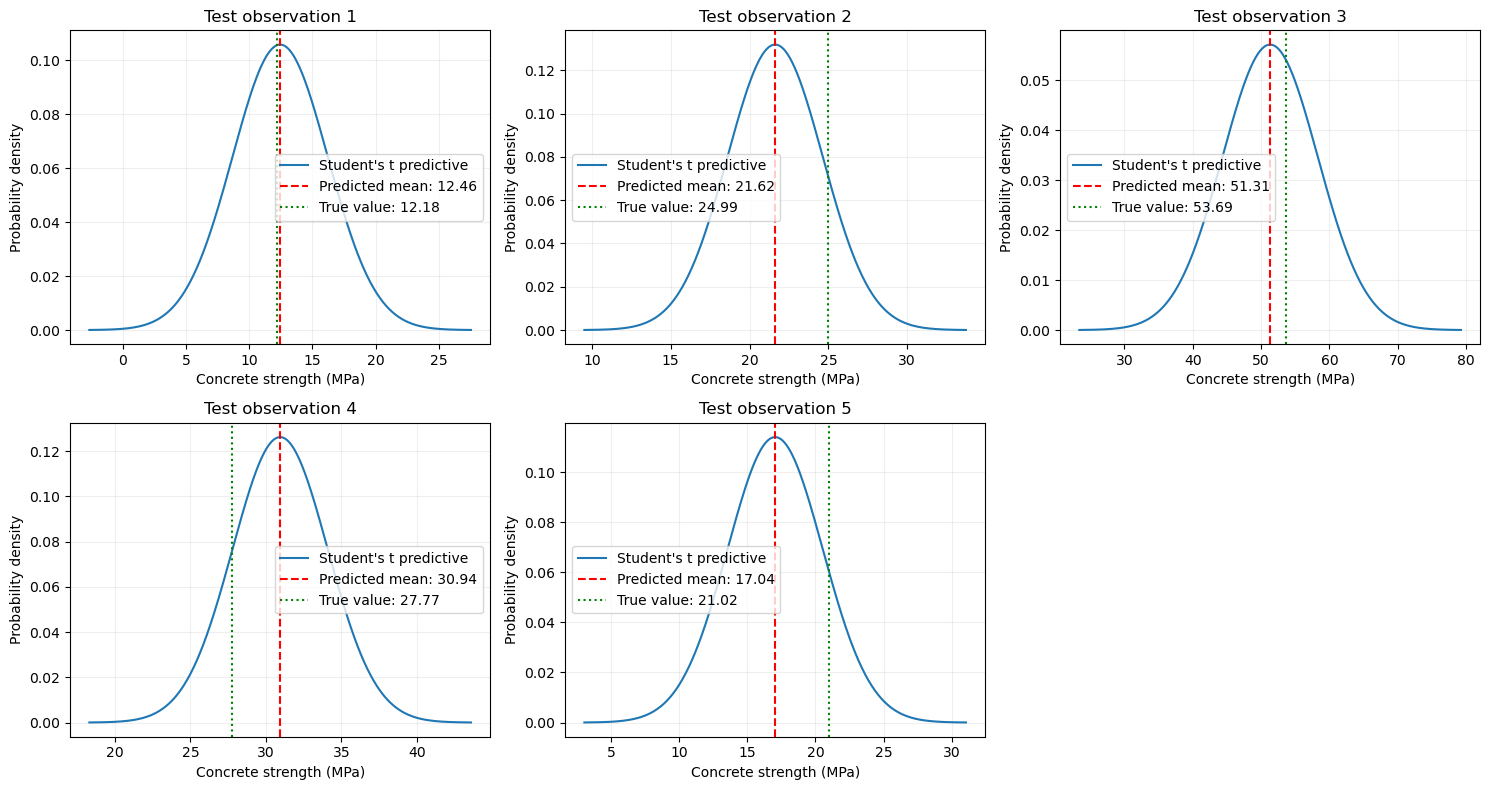

In [33]:
from math import lgamma

a = np.asarray(an).item()
b = np.asarray(bn).item()

v = 2 * a
indices = [0, 1, 2, 3, 4]  # Test observations to plot

# Compute S_N @ phi for all five observations
selected_phi = phi_test[indices]
Sn_phi = np.linalg.solve(Sn_inv, selected_phi.T)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for position, i in enumerate(indices):
    phi_x = phi_test[i].reshape(-1, 1)

    mu = (phi_x.T @ mn).item()

    # phi(x)^T @ S_N @ phi(x)
    quadratic_term = (
        phi_x.T @ Sn_phi[:, position:position + 1]
    ).item()

    #  precision parameter, lambda
    lam = a / (b * (1 + quadratic_term))

    scale = 1 / np.sqrt(lam)
    true_val = test_y[i]

    # Include the true value in the horizontal range
    lower = min(mu - 4 * scale, true_val - scale)
    upper = max(mu + 4 * scale, true_val + scale)

    t = np.linspace(lower, upper, 600)

    # Student's t density using v and lambda
    # Logarithms avoid overflow in the Gamma functions
    log_density = (
        lgamma((v + 1) / 2)
        - lgamma(v / 2)
        + 0.5 * (np.log(lam) - np.log(np.pi * v))
        - ((v + 1) / 2)
          * np.log1p(lam * (t - mu)**2 / v)
    )

    density = np.exp(log_density)

    ax = axes[position]

    ax.plot(t, density, label="Student's t predictive")
    ax.axvline(
        mu,
        color="red",
        linestyle="--",
        label=f"Predicted mean: {mu:.2f}"
    )
    ax.axvline(
        true_val,
        color="green",
        linestyle=":",
        label=f"True value: {true_val:.2f}"
    )

    ax.set_title(f"Test observation {i + 1}")
    ax.set_xlabel("Concrete strength (MPa)")
    ax.set_ylabel("Probability density")
    ax.legend()
    ax.grid(alpha=0.2)

axes[5].axis("off")

plt.tight_layout()
plt.show()

For a point estimate of $\vec{w}$ the most probable value depends only on the Normal distribution and therefore is $\vec{m_N}$ as mode=mean 

In [34]:
# Point predictions for all test observations
predictions = (phi_test @ mn).ravel()
actual = np.asarray(test_y).ravel()

rmse = np.sqrt(np.mean((actual - predictions)**2))

print(f"Test RMSE: {rmse:.4f} MPa")

Test RMSE: 3.9049 MPa
